
# Lab 9: Quantun Computing - Rabi Oscillations

Nombre estudiante: Critsian Alexis Gómez Jaramillo

c.c: 1001360613

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

## Exercise 1: $NH_3$ molecule

An example of the quantum oscillations in two-level systems may be rather unexpected; for example, the ammonium molecule 

![NH3](../Sesiones/QC/figures/NH3.png)
![NH3](NH3.png)

 It has two symmetric states that differ by the inversion of the nitrogen atom relative to the plane of the three hydrogen atoms, which are weakly coupled due to quantum-mechanical tunneling of the nitrogen atom through the plane of the hydrogen atoms. Since for this particular molecule, in the absence of external fields, the level splitting $\Delta E$ corresponds to an experimentally convenient frequency $\Omega/2\pi\approx$ 24.79 GHz.

 1. Supose a detuning frequency $\Omega_R/2$.
 2. Compute the Rabi frequency for NH3 molecule in Hz and do a plot of the Rabi oscillation. Supose that the initial state is $\ket{2}$.
 
 [see](https://phys.libretexts.org/Bookshelves/Quantum_Mechanics/Essential_Graduate_Physics_-_Quantum_Mechanics_(Likharev)/05%3A_Some_Exactly_Solvable_Problems/5.01%3A_Two-level_Systems)

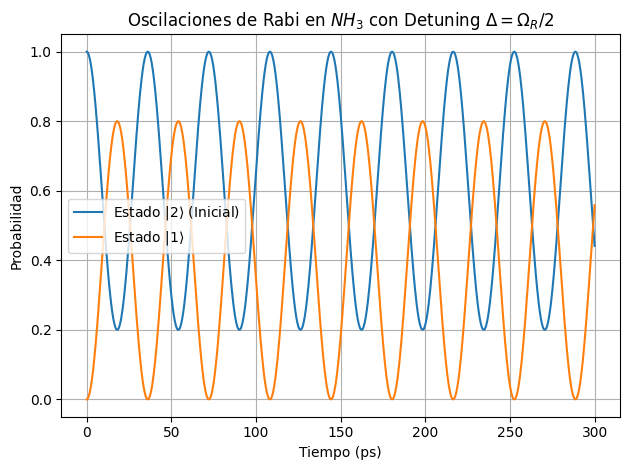

In [17]:
f_R=24.79e9             # Frecuencia de Rabi en Hz (24.79 GHz)
Omega_R=2*np.pi*f_R     # Frecuencia angular de Rabi (rad/s)

Delta=Omega_R/2

# Frecuencia de Rabi generalizada/efectiva
Omega_eff=np.sqrt(Omega_R**2+Delta**2)

t = np.linspace(0, 300e-12, 1000)

amplitud=(Omega_R/Omega_eff)**2

P1=amplitud*np.sin(Omega_eff*t/2)**2

P2=1-P1

plt.plot(t*1e12,P2,label=r'Estado $|2\rangle$ (Inicial)')
plt.plot(t*1e12,P1,label=r'Estado $|1\rangle$')
plt.xlabel('Tiempo (ps)')
plt.ylabel('Probabilidad')
plt.title(r'Oscilaciones de Rabi en $NH_3$ con Detuning $\Delta = \Omega_R / 2$')
plt.legend()
plt.grid()
plt.ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()

## Exercise: Bell state

1. Creates a quantum circuit for two qubits, consisting of the quantum gates needed to create a `Bell state`  (two entangled qubits). The quantum circuit then terminates with quantum measurements, extracting one bit from each qubit.

Resultados de medición (Estado de Bell): {'11': 519, '00': 481}


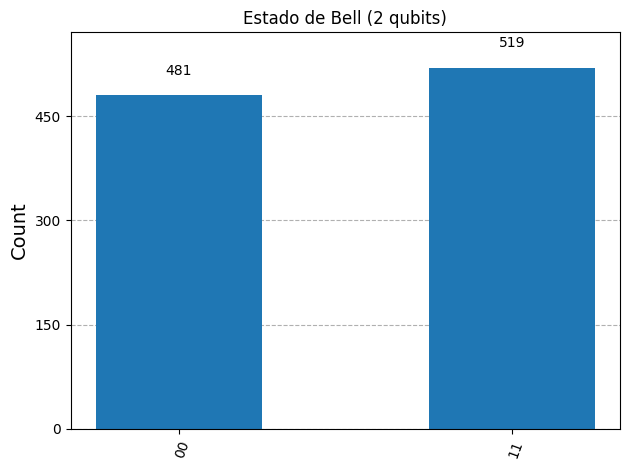

In [18]:
simulator=AerSimulator()

# Circuito con 2 qubits y 2 bits clásicos
qc1=QuantumCircuit(2, 2)

# Crear el estado de Bell (|Φ+⟩)
qc1.h(0)
qc1.cx(0,1)

# Medición
qc1.measure([0,1],[0,1])

compiled_circuit1=transpile(qc1,simulator)
result1=simulator.run(compiled_circuit1,shots=1000).result()
counts1=result1.get_counts(qc1)

print("Resultados de medición (Estado de Bell):",counts1)

plot_histogram(counts1, title="Estado de Bell (2 qubits)")

2. Add a third qubit by changing to QuantumCircuit(3), and add a second CX gate with qc.cx(1,2). The measurements should then change to 000 and 111, which means all three of these qubits have been entangled.

Resultados de medición (3 qubits): {'000': 500, '111': 500}


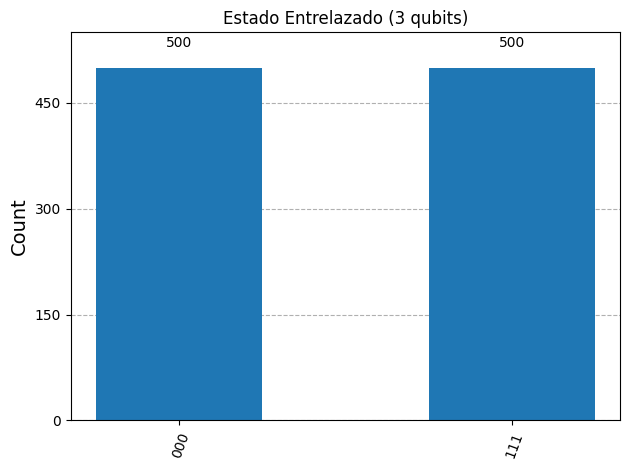

In [19]:
# Circuito con 3 qubits y 3 bits clásicos
qc2 = QuantumCircuit(3, 3)

qc2.h(0)
qc2.cx(0,1)
qc2.cx(1,2)

# Medición
qc2.measure([0,1,2],[0,1,2])

compiled_circuit2=transpile(qc2,simulator)
result2=simulator.run(compiled_circuit2,shots=1000).result()
counts2=result2.get_counts(qc2)

print("Resultados de medición (3 qubits):",counts2)

plot_histogram(counts2,title="Estado Entrelazado (3 qubits)")

3. See your results shift by adding qc.x(1) to the end of the circuit.

Resultados con qc.x(1): {'010': 519, '001': 481}


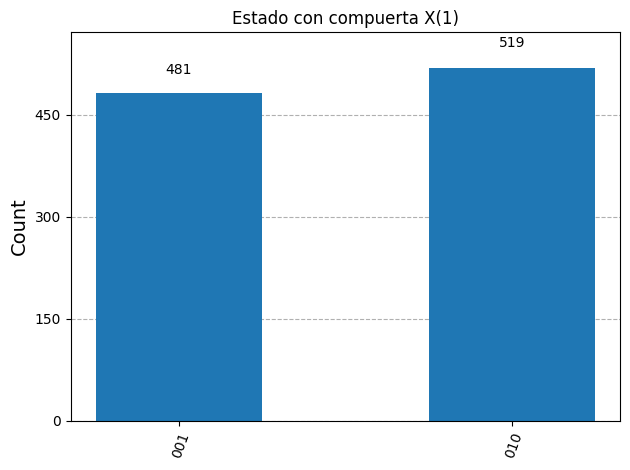

In [20]:
qc3 = QuantumCircuit(3, 3)

qc3.h(0)
qc3.cx(0,1)

qc3.x(1)           

# Medición
qc3.measure([0,1,2],[0,1,2])

compiled_circuit3=transpile(qc3,simulator)
result3=simulator.run(compiled_circuit3,shots=1000).result()
counts3=result3.get_counts(qc3)

print("Resultados con qc.x(1):",counts3)

plot_histogram(counts3,title="Estado con compuerta X(1)")